# Final analysis and recommendations

This notebook pulls the team's analyses into one story and shows how each finding supports a recommendation. It reads the saved outputs of the other notebooks, so every number traces back to a source notebook and file. Run the other notebooks first if an output is missing.

**Goal:** help affected members move to FFS without losing care. IEHP is not trying to prevent the planned transition. Financial monitoring supports that goal.

| Question | Evidence | Source notebook |
|---|---|---|
| How many members, and who? | Reconciled counts, county demographics | Source B, Source E (section 9) |
| Where could access fail? | ZIP ranking, sensitivity, high-confidence gaps | Source E (sections 8 to 8b) |
| What does it cost IEHP? | Net effect, patient mix, fixed cost | Financial (sections 5 to 12b) |
| What should IEHP do and track? | Three recommendations, baselines | This notebook |

**Where the numbers come from.** Each section ends with a short source note. **Section 7 lists every number we cite** with its original source, date, type and the file or notebook section that produces it, so each figure can be defended or rechecked.

**Number types used throughout**
- **Sourced:** read directly from a public data file or the student workbook.
- **Sourced (email):** from the Q&A guidance email. Not in the repository, so we cannot recheck it ourselves.
- **Derived:** our arithmetic on sourced numbers.
- **Modeled:** results of the financial model, which rests on the workbook's assumptions.
- **Team assumption:** a choice we made and say so.

In [19]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown as _Markdown, display

def Markdown(text):
    """Escape dollar signs so dollar amounts are not read as math."""
    return _Markdown(text.replace("$", r"\$"))

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis_outputs").is_dir()), None)
if root is None:
    raise FileNotFoundError("Start Jupyter from the repository folder.")
out = root / "analysis_outputs"
acc, fin, srcb = out / "access", out / "financial", out / "source_b"

def read(path, **kw):
    if not path.is_file():
        raise FileNotFoundError(f"{path.name} is missing. Run the notebook that creates it first.")
    return pd.read_csv(path, **kw)

zip_str = {"ZIP": "string"}
ranking = read(acc / "zip_access_ranking.csv", dtype=zip_str).sort_values("Rank")
gaps = read(acc / "high_confidence_gap_zips.csv", dtype=zip_str)
conv = read(acc / "provider_conversion_whatif.csv", dtype=zip_str)
sens = read(acc / "ranking_sensitivity.csv")
recon = read(acc / "number_reconciliation.csv")
baseline = read(acc / "monitoring_baseline.csv")
case = read(fin / "iehp_estimate_case.csv", index_col=0)["IEHP estimate"]
scen = read(fin / "scenario_results.csv", index_col=0)
mix = read(fin / "net_by_share_and_mix.csv", index_col=0)
age = read(srcb / "latest_age_summary.csv")
lang = read(srcb / "latest_language_summary.csv")

def money(x):
    sign = "-" if x < 0 else ""
    return f"{sign}${abs(x) / 1e6:,.0f}M"

print("Loaded outputs from", out.relative_to(root))

Loaded outputs from analysis_outputs


## 1. How many members, and who are they?

Several counts describe overlapping groups, so each is used for one job only. IEHP's own estimate (119,600) is the planning base case. The county UIS count is context, and the guide's 10% to 18% cases are sensitivity.

Source B describes **all Medi-Cal members in the two counties**. It shows the region the transition lands in, not who the UIS members are.

In [20]:
display(recon.assign(Value=recon["Value"].map("{:,}".format)))

val = lambda measure, source=None: int(recon.loc[recon["Measure"].eq(measure) & (recon["Source"].str.contains(source) if source else True), "Value"].iloc[0])
iehp_est = val("IEHP estimated transitioning")
source_d = val("IEHP Medi-Cal enrollment")
uis_counties = val("UIS members, two counties")
ffs_now = val("Already in FFS, two counties")

children = age.loc[age["Age Group"].eq("Age 00-18"), "Count"].sum() / age["Count"].sum()
seniors = age.loc[age["Age Group"].eq("Age 65+"), "Count"].sum() / age["Count"].sum()
lang_all = lang[lang["complete"]].groupby("Language")["Count"].sum()
spanish = lang_all["Spanish"] / lang_all.sum()

display(Markdown(f"""
**Reading the table**
- IEHP's estimate is **{iehp_est / source_d:.1%}** of its Medi-Cal enrollment and **{iehp_est / uis_counties:.0%}** of the county UIS count (a derived ratio). It sits below the guide's 10% low case.
- FFS in the two counties would grow about **{(ffs_now + iehp_est) / ffs_now:.1f}x** from {ffs_now:,} (September 2026) if all {iehp_est:,} move.
- Regional context, Source B (October 2026, preliminary): children are **{children:.0%}** of Medi-Cal members, ages 65+ are **{seniors:.0%}**, and Spanish is the primary language for **{spanish:.0%}** of members with a reported language. These describe the region, not the transitioning group.
"""))

,Measure,Value,Source,Date,Use it for
0,"All Medi-Cal, two counties","1,805,023","Source A, ZIP file, residential-weighted",Sep 2026 (prelim.),"ZIP-level demand. Visible ZIP counts only, may understate"
1,"All Medi-Cal, two counties","1,817,318","Source B, age and sex table",Sep 2026 (prelim.),"County demographics. Compare with Source A, not with IEHP"
2,"All Medi-Cal, two counties","1,783,874","Source B, age and sex table",Oct 2026 (prelim.),Latest month. Use the month that matches your other numbers
3,IEHP Medi-Cal enrollment,"1,363,303","Source D, State enrollment report",Sep 2026 (prelim.),IEHP size in the financial model
4,"IEHP Medi-Cal, fact sheet","1,321,983","Source C, IEHP fact sheet via workbook",Oct 2026,"Footnote only. Excludes DualChoice, which likely explains the gap to Source D"
5,"Already in FFS, two counties","99,206","Source B, delivery system table",Sep 2026 (prelim.),Baseline for how much FFS grows
6,"UIS members, two counties","172,459",DHCS via Q&A email,Jun 2026,Broader than IEHP's group. Not a January count
7,IEHP estimated transitioning,"119,600",IEHP via Q&A email,Latest IEHP estimate,Planning base case. Use scenarios around it



**Reading the table**
- IEHP's estimate is **8.8%** of its Medi-Cal enrollment and **69%** of the county UIS count (a derived ratio). It sits below the guide's 10% low case.
- FFS in the two counties would grow about **2.2x** from 99,206 (September 2026) if all 119,600 move.
- Regional context, Source B (October 2026, preliminary): children are **38%** of Medi-Cal members, ages 65+ are **10%**, and Spanish is the primary language for **22%** of members with a reported language. These describe the region, not the transitioning group.


*Sources for this section:* IEHP enrollment is DHCS managed care enrollment, September 2026 (Source D). FFS members are DHCS certified eligibles by delivery system, September 2026 (Source B). Age and language shares are DHCS certified eligibles by age and sex and by primary language, October 2026 (Source B). The 119,600 estimate and the county UIS counts are from the Q&A guidance email. All recent months are preliminary. Details in Section 7.

## 2. Where could access fail?

ZIPs are ranked by estimated transitioning members per listed FFS primary-care provider (September 2026 demand, October 26, 2026 provider list). The estimate is spread across ZIPs in proportion to Medi-Cal members, which is an assumption. Enrollment on the provider list is not new-patient acceptance, so this ranking says **where to verify first**, not where care definitely does not exist.

,ZIP,City,Main_County,Medi-Cal members,Est_Transition_A,PCPs
Rank,,,,,,
1,92240,DESERT HOT SPRINGS,Riverside,24138.0,1597.0,0
2,92551,MORENO VALLEY,Riverside,15561.0,1029.0,0
3,92880,EASTVALE,Riverside,14003.0,926.0,0
4,92274,THERMAL,Riverside,12624.0,835.0,0
5,92596,WINCHESTER,Riverside,10225.0,676.0,0
6,92582,SAN JACINTO,Riverside,10129.0,670.0,0
7,92344,HESPERIA,San Bernardino,9839.0,651.0,0
8,92254,MECCA,Riverside,9672.0,640.0,0
9,92532,LAKE ELSINORE,Riverside,8557.0,566.0,0


Slide images exported to: analysis_outputs\slide_exports
PNG: access_top10_and_scatter_CPP_Inter.png
SVG: access_top10_and_scatter_CPP_Inter.svg


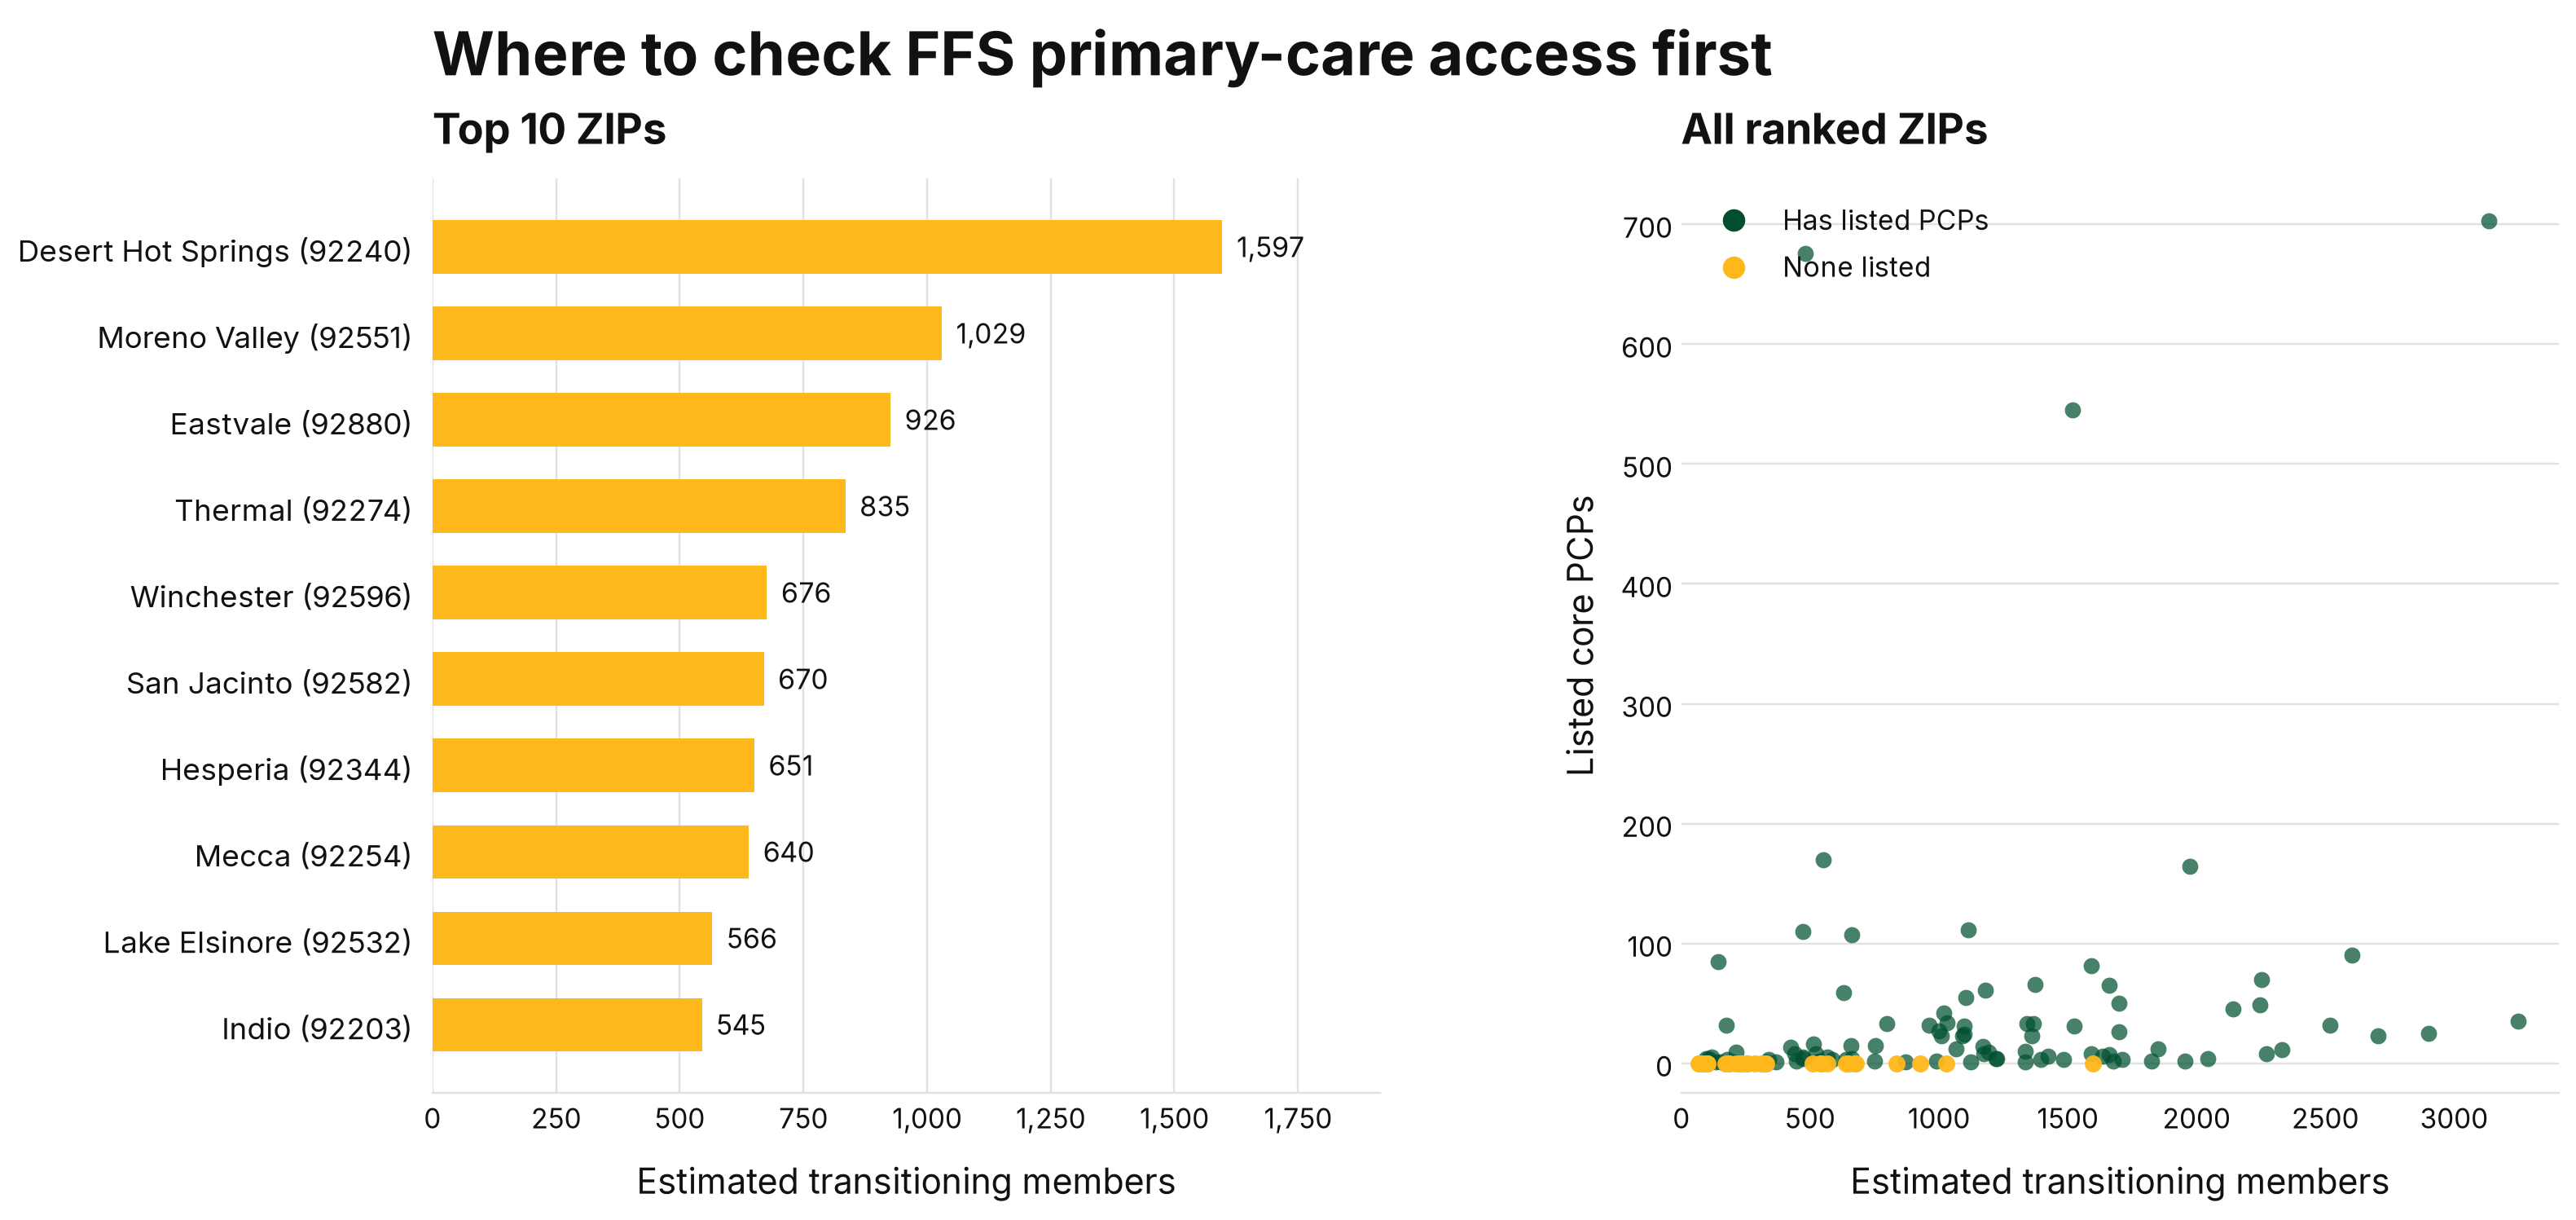

In [21]:
n_ranked, n_nopcp = len(ranking), int(ranking["PCPs"].eq(0).sum())
top10 = ranking.head(10)
robust = sorted(set(top10["ZIP"]) & set(gaps["ZIP"]))
robust_names = ", ".join(f"{c.title()} ({z})" for z, c in zip(top10["ZIP"], top10["City"]) if z in robust)
top10_riverside = int(top10["Main_County"].eq("Riverside").sum())
gap_members = gaps["Est_Transition_A"].sum()
providers_top10 = int(conv["Providers to reach median TPP"].sum())

display(top10[["Rank", "ZIP", "City", "Main_County", "Medi-Cal members", "Est_Transition_A", "PCPs"]].round(0).set_index("Rank"))
# Export the top-10 bar chart and the all-ZIP provider scatterplot.
from matplotlib import font_manager
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

font_dir = root / "analysis_outputs" / "slide_exports" / "fonts"
for font_file in (font_dir / "Inter-Regular.ttf", font_dir / "Inter-Bold.ttf"):
    if not font_file.is_file():
        raise FileNotFoundError(f"Bundled Inter font not found: {font_file}")
    font_manager.fontManager.addfont(str(font_file))

cpp_green, cpp_gold = "#005030", "#FFB81C"
ink, muted, rule = "#111111", "#111111", "#E1E1E1"
plt.rcParams.update({
    "font.family": "Inter", "font.size": 13, "text.color": ink,
    "axes.labelcolor": ink, "xtick.color": ink, "ytick.color": ink,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": rule, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": rule, "grid.linewidth": 0.8, "svg.fonttype": "none",
})

export_dir = root / "analysis_outputs" / "slide_exports"
export_dir.mkdir(parents=True, exist_ok=True)
chart_top10 = ranking.head(10).copy()
fig, (ax_bar, ax_scatter) = plt.subplots(1, 2, figsize=(13.33, 7.5), gridspec_kw={"width_ratios": [1.08, 1.0]})
fig.suptitle("Where to check FFS primary-care access first", x=0.08, y=0.95, ha="left", fontsize=24, fontweight="bold", color=ink)
labels = [f"{str(city).title()} ({zip_code})" for city, zip_code in zip(chart_top10["City"], chart_top10["ZIP"])]
values = chart_top10["Est_Transition_A"].astype(float).to_numpy()
ypos = range(len(chart_top10))
ax_bar.barh(ypos, values, height=0.62, color=cpp_gold)
ax_bar.set_yticks(list(ypos), labels)
ax_bar.invert_yaxis()
ax_bar.set_title("Top 10 ZIPs", loc="left", fontsize=17, fontweight="bold", pad=14, color=ink)
ax_bar.set_xlabel("Estimated transitioning members", labelpad=10, fontsize=14, color=ink)
ax_bar.tick_params(axis="y", length=0, labelsize=12, pad=8)
ax_bar.tick_params(axis="x", length=0, labelsize=11)
ax_bar.grid(axis="y", visible=False)
ax_bar.set_xlim(0, max(values) * 1.2)
ax_bar.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
for y, value in zip(ypos, values):
    ax_bar.text(value + max(values) * 0.018, y, f"{value:,.0f}", va="center", fontsize=11, color=ink)

has_pcp = ranking["PCPs"].gt(0)
no_pcp = ~has_pcp
ax_scatter.scatter(ranking.loc[has_pcp, "Est_Transition_A"], ranking.loc[has_pcp, "PCPs"], s=42, color=cpp_green, alpha=0.72, linewidths=0, zorder=2)
ax_scatter.scatter(ranking.loc[no_pcp, "Est_Transition_A"], ranking.loc[no_pcp, "PCPs"], s=47, color=cpp_gold, alpha=0.95, linewidths=0, zorder=2)
ax_scatter.set_title("All ranked ZIPs", loc="left", fontsize=17, fontweight="bold", pad=14, color=ink)
ax_scatter.set_xlabel("Estimated transitioning members", labelpad=10, fontsize=14, color=ink)
ax_scatter.set_ylabel("Listed core PCPs", labelpad=8, fontsize=14, color=ink)
ax_scatter.tick_params(axis="both", length=0, labelsize=11)
ax_scatter.grid(axis="x", visible=False)
ax_scatter.set_xlim(left=0)
ax_scatter.set_ylim(bottom=-25)
ax_scatter.legend(handles=[
    Line2D([], [], marker="o", linestyle="None", markersize=8, color=cpp_green, label="Has listed PCPs"),
    Line2D([], [], marker="o", linestyle="None", markersize=8, color=cpp_gold, label="None listed"),
], frameon=False, loc="upper left", fontsize=11)
fig.subplots_adjust(left=0.08, right=0.97, top=0.83, bottom=0.15, wspace=0.33)
png_path = export_dir / "access_top10_and_scatter_CPP_Inter.png"
svg_path = export_dir / "access_top10_and_scatter_CPP_Inter.svg"
fig.savefig(png_path, dpi=220, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.close(fig)
print("Slide images exported to:", export_dir.relative_to(root))
print("PNG:", png_path.name)
print("SVG:", svg_path.name)
display(Image(filename=str(png_path)))

core_only = sens[sens["Provider definition"].isin(["PCP core", "PCP core, minus reported N/M"])]
broad_defs = sens[~sens.index.isin(core_only.index)]


*Sources for this section:* demand is DHCS Medi-Cal certified eligibles by ZIP, September 2026, preliminary (Source A). Supply is the DHCS Medi-Cal FFS provider listing as of October 26, 2026 (Source E). ZIP-to-county assignment uses the June 2026 ZIP-county crosswalk (Source H). Primary care is defined by us as individual physicians in Family, General Practice, Internal Medicine, Pediatrics or Geriatrics. Spreading 119,600 across ZIPs and ranking only ZIPs with at least 1,000 Medi-Cal members are team assumptions. Details in Section 7.

## 3. What does it cost IEHP?

The financial model rebuilds the student workbook. Losing revenue is not the same as losing that much money, because IEHP also stops paying the medical bills for members who leave. What remains is mostly **fixed overhead spread over fewer members**, and the answer swings with **who** leaves. Mix and cost assumptions are the workbook's, not IEHP's.

In [22]:
net = {k: scen.loc["net_iehp", k] for k in ["Low", "Middle", "High"]}
rev = {k: scen.loc["revenue_lost", k] for k in ["Low", "Middle", "High"]}
mix_label = {"Healthier": mix.index[0], "Base": mix.index[1], "Sicker": mix.index[2]}
mix_swing = mix.loc[mix_label["Sicker"], "Middle"] - mix.loc[mix_label["Healthier"], "Middle"]
headcount_swing = net["Low"] - net["High"]

view = pd.DataFrame({
    "IEHP estimate (119,600)": [case["Revenue lost"], case["Medical bills avoided"], case["NET EFFECT ON IEHP"],
                                case["Net if healthier members leave"], case["Net if sicker members leave"],
                                case["Fixed cost per member per month, no action"], case["Stoplight with no action"]],
    "Guide low (10%)": [money(rev["Low"]), money(scen.loc["medical_avoided", "Low"]), money(net["Low"]),
                        money(mix.loc[mix_label["Healthier"], "Low"]), money(mix.loc[mix_label["Sicker"], "Low"]), "", ""],
    "Guide high (18%)": [money(rev["High"]), money(scen.loc["medical_avoided", "High"]), money(net["High"]),
                         money(mix.loc[mix_label["Healthier"], "High"]), money(mix.loc[mix_label["Sicker"], "High"]), "", ""],
}, index=["Revenue lost", "Medical bills avoided", "Net effect on IEHP (base mix)", "Net if healthier members leave",
          "Net if sicker members leave", "Fixed cost per member per month, no action", "Stoplight, no action"])
display(view)

display(Markdown(f"""
**What the numbers say**
- At IEHP's own estimate the net effect is about **{case['NET EFFECT ON IEHP']}** a year at the base mix, roughly **{case['Times the budgeted surplus']}** the budgeted surplus. Most lost revenue is offset by medical bills IEHP no longer pays.
- **Who leaves matters more than how many.** At the guide's middle case, the healthier-to-sicker swing is {money(mix_swing)}, about **{mix_swing / headcount_swing:.1f}x** the swing from changing headcount from 10% to 18%. IEHP cannot choose who leaves, but it can measure the mix early with its own claims data.
- **Overhead is the pressure point.** Fixed cost per remaining member rises to {case['Fixed cost per member per month, no action']} with no action ({case['Stoplight with no action']} on the team's sample stoplight, which is an assumption).
- The range is wide ({case['Net if healthier members leave']} to {case['Net if sicker members leave']}), so the recommendation should be **triggers and monitoring**, not a single forecast.
"""))

,"IEHP estimate (119,600)",Guide low (10%),Guide high (18%)
Revenue lost,$991M,"$1,129M","$2,032M"
Medical bills avoided,$938M,"$1,069M","$1,924M"
Net effect on IEHP (base mix),-$29.3M,-$33M,-$60M
Net if healthier members leave,-$85.9M,-$98M,-$176M
Net if sicker members leave,$55.7M,$63M,$114M
"Fixed cost per member per month, no action",$19.41 (+9.4%),,
"Stoplight, no action",Yellow,,



**What the numbers say**
- At IEHP's own estimate the net effect is about **-\$29.3M** a year at the base mix, roughly **1.0x** the budgeted surplus. Most lost revenue is offset by medical bills IEHP no longer pays.
- **Who leaves matters more than how many.** At the guide's middle case, the healthier-to-sicker swing is \$230M, about **8.6x** the swing from changing headcount from 10% to 18%. IEHP cannot choose who leaves, but it can measure the mix early with its own claims data.
- **Overhead is the pressure point.** Fixed cost per remaining member rises to \$19.41 (+9.4%) with no action (Yellow on the team's sample stoplight, which is an assumption).
- The range is wide (-\$85.9M to \$55.7M), so the recommendation should be **triggers and monitoring**, not a single forecast.


*Sources for this section:* these results come from the student financial workbook, which uses DHCS CY2026 payment rates and IEHP's CY2026 budget as described in its notes. We rebuilt the workbook's calculations and checked that they match its cells. Member mix, chronic-condition shares and the 60% fixed-overhead share are workbook assumptions, not IEHP data. The stoplight level in the fixed-cost result is a team assumption. All figures are modeled yearly planning estimates, not forecasts. Details in Section 7.

## 4. Putting it together: what the evidence supports

Our starting thesis was provisional. This table checks each part against the data and states how far each finding can be trusted.

In [23]:
matrix = pd.DataFrame([
    ("A large group needs a handoff",
     f"{iehp_est:,} IEHP members expected to move ({iehp_est / source_d:.1%} of enrollment). FFS grows about {(ffs_now + iehp_est) / ffs_now:.1f}x.",
     "High for size (IEHP estimate, not final)", "1, 2, 3"),
    ("Access pressure is uneven across places",
     f"{n_nopcp} of {n_ranked} ranked ZIPs list no FFS core primary care. {len(gaps)} list none under the broadest definition.",
     "Medium: depends on the provider definition and on the ZIP allocation assumption", "2"),
    ("Some places are gaps under every definition tested",
     f"{robust_names} stay in the top 10 under all 8 variants.",
     "Medium-high as places to verify first", "2"),
    ("Provider enrollment is not access",
     "The FFS list excludes managed-care providers and shows new-patient acceptance for under 10% of rows.",
     "High (data limit)", "1, 2"),
    ("Region has many children, some older members, many Spanish speakers",
     f"Children {children:.0%}, ages 65+ {seniors:.0%}, Spanish primary language {spanish:.0%} (all Medi-Cal, not UIS).",
     "Medium: regional context only", "1"),
    ("The net money effect is modest but uncertain",
     f"Net about {case['NET EFFECT ON IEHP']} a year at the base mix; range {case['Net if healthier members leave']} to {case['Net if sicker members leave']}.",
     "Medium-low: workbook assumptions, not IEHP data", "3"),
    ("Overhead per remaining member is the pressure point",
     f"Fixed cost per member {case['Fixed cost per member per month, no action']} with no action.",
     "Medium: 60% fixed share is an assumption", "3"),
], columns=["Finding", "Evidence", "How far to trust it", "Supports recommendation"])
matrix.index = range(1, len(matrix) + 1)
pd.set_option("display.max_colwidth", None)
display(matrix)

display(Markdown("""
**Verdict on the starting thesis**
- **Where access may fail:** supported, and specific. Targeting beats a region-wide response.
- **Continuity for vulnerable members:** supported by the size of the move and the limits of the provider list, but our files cannot identify who needs a handoff. IEHP's own care-management data must do that.
- **Money is the main risk:** **not** supported as the lead story. The net effect is modest, and the open question is who leaves and what happens to overhead. Money stays a supporting recommendation.
"""))

,Finding,Evidence,How far to trust it,Supports recommendation
1,A large group needs a handoff,"119,600 IEHP members expected to move (8.8% of enrollment). FFS grows about 2.2x.","High for size (IEHP estimate, not final)","1, 2, 3"
2,Access pressure is uneven across places,34 of 126 ranked ZIPs list no FFS core primary care. 15 list none under the broadest definition.,Medium: depends on the provider definition and on the ZIP allocation assumption,2
3,Some places are gaps under every definition tested,"Winchester (92596), San Jacinto (92582), Lake Elsinore (92532) stay in the top 10 under all 8 variants.",Medium-high as places to verify first,2
4,Provider enrollment is not access,The FFS list excludes managed-care providers and shows new-patient acceptance for under 10% of rows.,High (data limit),"1, 2"
5,"Region has many children, some older members, many Spanish speakers","Children 38%, ages 65+ 10%, Spanish primary language 22% (all Medi-Cal, not UIS).",Medium: regional context only,1
6,The net money effect is modest but uncertain,Net about -$29.3M a year at the base mix; range -$85.9M to $55.7M.,"Medium-low: workbook assumptions, not IEHP data",3
7,Overhead per remaining member is the pressure point,Fixed cost per member $19.41 (+9.4%) with no action.,Medium: 60% fixed share is an assumption,3



**Verdict on the starting thesis**
- **Where access may fail:** supported, and specific. Targeting beats a region-wide response.
- **Continuity for vulnerable members:** supported by the size of the move and the limits of the provider list, but our files cannot identify who needs a handoff. IEHP's own care-management data must do that.
- **Money is the main risk:** **not** supported as the lead story. The net effect is modest, and the open question is who leaves and what happens to overhead. Money stays a supporting recommendation.


## 5. How the analysis feeds the three recommendations

Owner roles, timing and trigger levels are team proposals for the CEO to confirm. They are not sourced facts.

In [24]:
display(Markdown(f"""
### Recommendation 1: Give every affected member a warm handoff, starting with those with ongoing care needs

**Action.** Before January 1, 2027, contact affected members in their language and help each one find an FFS provider, understand next steps, and carry over medications, referrals and upcoming appointments. A simple digital tool can deliver this, but the handoff is the goal, not the tool. Prioritize members with active treatment using IEHP's care-management data. Do not target by immigration status or by demographics.

**Why (evidence).** {iehp_est:,} members are expected to move and FFS grows about {(ffs_now + iehp_est) / ffs_now:.1f}x (Section 1). The region is {children:.0%} children, with Spanish the primary language for {spanish:.0%} of members, so outreach must be multilingual (regional context only). Provider enrollment alone does not guarantee a place to go (Section 2).

**First 90 days.** Before Jan 1: build the contact list from IEHP data, draft the care summary, complete privacy and legal review. January to March: confirm a provider or appointment within 30 days for prioritized members.

**Metrics.** Members contacted; members with a verified provider or appointment within 30 days; medication and referral continuity; emergency visits after the move. IEHP sets baselines and targets.

**Main risk.** Contact data may be out of date, and members may avoid outreach. Offer safe contact options and keep privacy safeguards explicit.

---

### Recommendation 2: Verify and build FFS primary-care capacity where it looks thinnest

**Action.** Start with the ZIPs below. Call local providers to confirm who is enrolled and taking new FFS patients. Help IEHP-network providers enroll in FFS where that keeps members with their current doctor, and tell outreach teams where members can go.

**Why (evidence).** {n_nopcp} of {n_ranked} ranked ZIPs list no FFS core primary-care provider, led by {', '.join(c.title() for c in top10['City'].head(3))}. {len(gaps)} ZIPs list none under the broadest definition, led by {robust_names}. The ranking does not change with how the estimate is spread across ZIPs, but it does change with the provider definition, so field verification is the right first step (Section 2). Bringing the top 10 ZIPs to the regional median would take about {providers_top10} more enrolled providers (planning size).

**First 90 days.** Before Jan 1: verify the {len(gaps)} high-confidence gap ZIPs and the top 10. January to March: report enrolled providers and appointment availability by ZIP monthly.

**Metrics.** Providers confirmed accepting FFS patients by ZIP; ranked ZIPs with no listed provider (baseline {n_nopcp} of {n_ranked}); time to first primary-care appointment; member access complaints.

**Main risk.** A ZIP with no listing may already be served by other plans' providers, so some effort could be wasted. Verification before investment limits this.

---

### Recommendation 3: Run the transition like a monitored program with preset triggers

**Action.** Set a short list of before-and-after measures, review them monthly, and agree in advance what IEHP does when a measure turns red. Include finance and operations: track fixed cost per remaining member and move staff into transition work before any cuts. Use IEHP's own claims to replace the workbook's assumptions about who is leaving.

**Why (evidence).** The net effect is about {case['NET EFFECT ON IEHP']} a year at IEHP's estimate, but it ranges from {case['Net if healthier members leave']} to {case['Net if sicker members leave']} depending on who leaves, and fixed cost per remaining member rises to {case['Fixed cost per member per month, no action']} with no action (Section 3). A range this wide is managed with triggers, not a forecast.

**First 90 days.** Before Jan 1: agree on baselines, trigger levels and owners; get IEHP's own count and mix of members moving. January to March: monthly review with a named owner for each red measure.

**Metrics and baselines.** See the table below. Items marked "IEHP to set" need IEHP data.

**Main risk.** Cost cuts could hurt care for remaining members. Redeploy first and protect member-facing and provider-support teams.
"""))
display(baseline)


### Recommendation 1: Give every affected member a warm handoff, starting with those with ongoing care needs

**Action.** Before January 1, 2027, contact affected members in their language and help each one find an FFS provider, understand next steps, and carry over medications, referrals and upcoming appointments. A simple digital tool can deliver this, but the handoff is the goal, not the tool. Prioritize members with active treatment using IEHP's care-management data. Do not target by immigration status or by demographics.

**Why (evidence).** 119,600 members are expected to move and FFS grows about 2.2x (Section 1). The region is 38% children, with Spanish the primary language for 22% of members, so outreach must be multilingual (regional context only). Provider enrollment alone does not guarantee a place to go (Section 2).

**First 90 days.** Before Jan 1: build the contact list from IEHP data, draft the care summary, complete privacy and legal review. January to March: confirm a provider or appointment within 30 days for prioritized members.

**Metrics.** Members contacted; members with a verified provider or appointment within 30 days; medication and referral continuity; emergency visits after the move. IEHP sets baselines and targets.

**Main risk.** Contact data may be out of date, and members may avoid outreach. Offer safe contact options and keep privacy safeguards explicit.

---

### Recommendation 2: Verify and build FFS primary-care capacity where it looks thinnest

**Action.** Start with the ZIPs below. Call local providers to confirm who is enrolled and taking new FFS patients. Help IEHP-network providers enroll in FFS where that keeps members with their current doctor, and tell outreach teams where members can go.

**Why (evidence).** 34 of 126 ranked ZIPs list no FFS core primary-care provider, led by Desert Hot Springs, Moreno Valley, Eastvale. 15 ZIPs list none under the broadest definition, led by Winchester (92596), San Jacinto (92582), Lake Elsinore (92532). The ranking does not change with how the estimate is spread across ZIPs, but it does change with the provider definition, so field verification is the right first step (Section 2). Bringing the top 10 ZIPs to the regional median would take about 118 more enrolled providers (planning size).

**First 90 days.** Before Jan 1: verify the 15 high-confidence gap ZIPs and the top 10. January to March: report enrolled providers and appointment availability by ZIP monthly.

**Metrics.** Providers confirmed accepting FFS patients by ZIP; ranked ZIPs with no listed provider (baseline 34 of 126); time to first primary-care appointment; member access complaints.

**Main risk.** A ZIP with no listing may already be served by other plans' providers, so some effort could be wasted. Verification before investment limits this.

---

### Recommendation 3: Run the transition like a monitored program with preset triggers

**Action.** Set a short list of before-and-after measures, review them monthly, and agree in advance what IEHP does when a measure turns red. Include finance and operations: track fixed cost per remaining member and move staff into transition work before any cuts. Use IEHP's own claims to replace the workbook's assumptions about who is leaving.

**Why (evidence).** The net effect is about -\$29.3M a year at IEHP's estimate, but it ranges from -\$85.9M to \$55.7M depending on who leaves, and fixed cost per remaining member rises to \$19.41 (+9.4%) with no action (Section 3). A range this wide is managed with triggers, not a forecast.

**First 90 days.** Before Jan 1: agree on baselines, trigger levels and owners; get IEHP's own count and mix of members moving. January to March: monthly review with a named owner for each red measure.

**Metrics and baselines.** See the table below. Items marked "IEHP to set" need IEHP data.

**Main risk.** Cost cuts could hurt care for remaining members. Redeploy first and protect member-facing and provider-support teams.


,Metric,Baseline,Source,Proposed owner (role),Proposed check
0,IEHP Medi-Cal enrollment,"1,363,303","Source D, Sep 2026",Finance lead,"Monthly vs this baseline; investigate a drop beyond what the 119,600 estimate explains"
1,"Members already in FFS, two counties","99,206","Source B, Sep 2026",Finance lead,"Expect a step up in January; track against 119,600"
2,"Listed FFS core PCPs per 1,000 Medi-Cal members",2.34,Sources A and E,Provider network lead,Rise in priority ZIPs after outreach
3,Ranked ZIPs with no listed core PCP,34 of 126,Sources A and E,Provider network lead,Fall as providers enroll; recheck monthly
4,Fixed operating cost per member per month,$17.75,"Workbook, 60% fixed share (assumption)",Chief Financial Officer,"Team stoplight: yellow above +5%, red above +10%"
5,Members with a verified FFS provider or appointment in 30 days,IEHP to set,IEHP data,Care management lead,Target set by IEHP before Jan 1
6,Medication and referral continuity rate,IEHP to set,IEHP data,Care management lead,Target set by IEHP before Jan 1
7,Emergency visits after transition,IEHP to set,IEHP data,Care management lead,Compare with the same members before the move


## 6. Limits and what to do before submitting

**Limits to say out loud**
- No file shows which ZIPs UIS members live in. The ZIP ranking spreads IEHP's 119,600 in proportion to Medi-Cal members, and Source A is all Medi-Cal, not UIS.
- The FFS provider list excludes managed-care providers and rarely shows new-patient acceptance. "No listed provider" means verify, not "no care".
- The 172,459 county UIS count and the 119,600 estimate come from the Q&A email. The DHCS county file and the CHCF brief it mentions are not in the repository.
- Financial results use the workbook's cost and member-mix assumptions, not IEHP's. Stoplight levels, the provider benchmark, owner roles and timing are team proposals.
- Recent months are preliminary. Source B's FFS count drops from September to October 2026 and we did not confirm why, so use September consistently.

**Next steps**
1. Confirm every number you will show matches a row in the reconciliation table and name its source and date on the slide.
2. Decide the provider definition you will show (core physicians only, or broader) and say so. The no-listed-provider count is 34 on one and 15 on the other.
3. If you can reach IEHP's materials, replace the workbook's mix and cost assumptions and the proportional ZIP allocation with IEHP's data.
4. Add a final AI-use slide and source labels next to numbers, as the case requires.

**Suggested five-minute flow**
| Time | Content |
|---|---|
| 0:00 to 0:30 | The answer: three actions to keep members connected to care |
| 0:30 to 1:15 | What changes on January 1, 2027, and how many members (119,600) |
| 1:15 to 2:30 | Where access may fail: top ZIPs and the high-confidence gaps |
| 2:30 to 3:15 | What it costs IEHP: net effect, who leaves, overhead |
| 3:15 to 4:30 | Recommendations with owners, first 90 days and metrics |
| 4:30 to 5:00 | Limits, sources and AI-use disclosure |

## 7. Source trail: where every number comes from

Use this as the reference sheet behind the video. Values are read from the saved outputs, so they match the numbers above. Months shown are the data month, not the date we pulled it.

File paths are relative to the repository. "Notebook section" names where the number is produced.

In [25]:
D_FILE = "data/demand-side/D-mediCal-managed-care-enrollment/open-data-portal-managed-care-enrollment-count-september-2026.csv"
B_DIR = "data/demand-side/B-medical-eligibles-by-demographics/"
A_FILE = "data/demand-side/A-medical-eligible-counts-by-ZIP/calendar-years-2020-to-the-most-recent-reportable-month.csv"
E_DIR = "data/provider-side/E-mediCal-fee-for-service-enrolled-providers/zipped_bc_too_big_for_github/"
H_FILE = "data/provider-side/H-county-zip-crosswalk/ZIP-COUNTY_062026.xlsx"
WORKBOOK = "docs/supplementary/student-guide-financial-impacts-modeling.xlsx"
QA = "Q&A guidance email (J. Yardley)"

broad_only = sens[~sens["Provider definition"].isin(["PCP core", "PCP core, minus reported N/M"])]

trail = [
    # number, value, type, original source, data month, where to find it
    ("IEHP estimated transitioning members", f"{iehp_est:,}", "Sourced (email)", f"IEHP estimate, shared in the {QA}", "Latest IEHP estimate", "Not in repo. Listed in analysis_outputs/access/number_reconciliation.csv"),
    ("UIS members, Riverside + San Bernardino", f"{uis_counties:,} (88,717 + 83,742)", "Sourced (email)", f"DHCS county UIS enrollment, shared in the {QA}", "Jun 2026", "Not in repo. Context only, not a January count"),
    ("IEHP Medi-Cal enrollment", f"{source_d:,}", "Sourced", f"DHCS managed care enrollment report (Source D). File: {D_FILE}", "Sep 2026, preliminary", "financial_impact_analysis.ipynb section 3; source_e_analysis.ipynb section 8"),
    ("IEHP estimate as share of enrollment", f"{iehp_est / source_d:.1%}", "Derived", "119,600 divided by IEHP Medi-Cal enrollment", "Sep 2026 base", "This notebook, Section 1"),
    ("IEHP estimate as share of county UIS count", f"{iehp_est / uis_counties:.0%}", "Derived", "119,600 divided by 172,459. Different groups, so a rough ratio only", "Jun 2026 / latest", "This notebook, Section 1"),
    ("Members already in FFS, two counties", f"{ffs_now:,}", "Sourced", f"DHCS certified eligibles by delivery system and plan (Source B). File: {B_DIR}by-delivery-system-and-plan-certified-eligibles.csv", "Sep 2026, preliminary", "source_e_analysis.ipynb section 9"),
    ("FFS growth if all 119,600 move", f"{(ffs_now + iehp_est) / ffs_now:.1f}x", "Derived", "(FFS today + 119,600) divided by FFS today", "Sep 2026 base", "This notebook, Section 1"),
    ("Children share of Medi-Cal members", f"{children:.0%}", "Sourced, then derived", f"DHCS certified eligibles by age and sex (Source B). File: {B_DIR}by-age-group-and-sex-certified-eligibles.csv", "Oct 2026, preliminary", "source_b_demographic_analysis.ipynb; analysis_outputs/source_b/latest_age_summary.csv"),
    ("Age 65+ share of Medi-Cal members", f"{seniors:.0%}", "Sourced, then derived", "Same table as above", "Oct 2026, preliminary", "Same file as above"),
    ("Spanish as primary language", f"{spanish:.0%}", "Sourced, then derived", f"DHCS certified eligibles by primary language (Source B). File: {B_DIR}by-primary-language-certified-eligibles.csv. Share of members with a reported language", "Oct 2026, preliminary", "analysis_outputs/source_b/latest_language_summary.csv"),
    ("ZIPs ranked / with no listed core PCP", f"{n_ranked} / {n_nopcp}", "Derived", f"Source A members by ZIP ({A_FILE}) with Source E provider listing ({E_DIR}) and Source H ZIP-county crosswalk ({H_FILE}). Only ZIPs with 1,000+ Medi-Cal members are ranked", "Sep 2026 demand; Oct 26, 2026 providers; Jun 2026 crosswalk", "source_e_analysis.ipynb sections 8 to 8a; analysis_outputs/access/zip_access_ranking.csv"),
    ("Primary-care definition", "Individual physicians: Family, General, Internal Medicine, Pediatrics, Geriatrics; one count per ZIP", "Team assumption", "Chosen by the team from Source E provider type and specialty codes", "Oct 26, 2026", "source_e_analysis.ipynb section 8"),
    ("ZIPs with no listed provider, broadest definition", f"{len(gaps)}", "Derived", "Core physicians plus nurse practitioners plus FFS clinic locations, from Source E", "Oct 26, 2026", "analysis_outputs/access/high_confidence_gap_zips.csv"),
    ("Top-10 overlap with broader provider definitions", f"{int(broad_only['Top-10 overlap with baseline'].min())} to {int(broad_only['Top-10 overlap with baseline'].max())} of 10", "Derived", "Overlap with the baseline top 10 when nurse practitioners and clinics are added, under two ways of spreading 119,600. Core-only variants match the baseline (10 of 10)", "Sep 2026 / Oct 26, 2026", "analysis_outputs/access/ranking_sensitivity.csv"),
    ("ZIP allocation of 119,600", "Proportional to ZIP Medi-Cal members (alternative: county UIS-weighted)", "Team assumption", "No file shows where UIS members live", "n/a", "source_e_analysis.ipynb section 8"),
    ("Providers to bring top 10 ZIPs to median pressure", f"{providers_top10}", "Derived, team benchmark", "Benchmark is the median estimated members per provider among ranked ZIPs that have one. A planning size, not a standard", "Sep 2026 / Oct 26, 2026", "analysis_outputs/access/provider_conversion_whatif.csv"),
    ("Net effect on IEHP at 119,600, base mix", case["NET EFFECT ON IEHP"], "Modeled", f"Student financial workbook ({WORKBOOK}), rebuilt in the notebook and checked against the workbook's cells", "CY2026 rates and budget", "financial_impact_analysis.ipynb section 12b; analysis_outputs/financial/iehp_estimate_case.csv"),
    ("Net effect, healthier vs sicker members leave", f"{case['Net if healthier members leave']} to {case['Net if sicker members leave']}", "Modeled", "Same model with the share of chronic-condition members leaving set to 40% or 65% (workbook what-ifs)", "CY2026", "financial_impact_analysis.ipynb sections 6 and 12b"),
    ("Net effect at the guide's 10% and 18% cases", f"{money(net['Low'])} to {money(net['High'])}", "Modeled", "Same model at 10% and 18% of Source D enrollment, the percentages in the case guide", "CY2026", "analysis_outputs/financial/scenario_results.csv"),
    ("Fixed cost per member per month, no action", case["Fixed cost per member per month, no action"], "Modeled", "Operating cost per member from IEHP's CY2026 budget in the workbook, times a 60% fixed share, spread over remaining members", "CY2026", "financial_impact_analysis.ipynb sections 8 and 12b"),
    ("Fixed share of operating cost (60%)", "60%", "Team/workbook assumption", "Workbook assumption, tested at 40% to 80%", "n/a", "financial_impact_analysis.ipynb section 7"),
    ("Stoplight result (levels: yellow above +5%, red above +10%)", f"{case['Stoplight with no action']} at 119,600", "Team assumption", "Example levels for the team to choose, not sourced", "n/a", "financial_impact_analysis.ipynb section 8"),
    ("Multiple of budgeted surplus", case["Times the budgeted surplus"], "Derived", "Net effect divided by IEHP's budgeted CY2026 surplus of $1.82 per member per month, from the workbook", "CY2026", "financial_impact_analysis.ipynb section 8"),
]
trail = pd.DataFrame(trail, columns=["Number", "Value", "Type", "Original source", "Data month", "Where to find it"])
trail.index = range(1, len(trail) + 1)
trail.to_csv(acc / "number_traceability.csv", index_label="#")
pd.set_option("display.max_colwidth", None)
display(trail)

,Number,Value,Type,Original source,Data month,Where to find it
1,IEHP estimated transitioning members,"119,600",Sourced (email),"IEHP estimate, shared in the Q&A guidance email (J. Yardley)",Latest IEHP estimate,Not in repo. Listed in analysis_outputs/access/number_reconciliation.csv
2,"UIS members, Riverside + San Bernardino","172,459 (88,717 + 83,742)",Sourced (email),"DHCS county UIS enrollment, shared in the Q&A guidance email (J. Yardley)",Jun 2026,"Not in repo. Context only, not a January count"
3,IEHP Medi-Cal enrollment,"1,363,303",Sourced,DHCS managed care enrollment report (Source D). File: data/demand-side/D-mediCal-managed-care-enrollment/open-data-portal-managed-care-enrollment-count-september-2026.csv,"Sep 2026, preliminary",financial_impact_analysis.ipynb section 3; source_e_analysis.ipynb section 8
4,IEHP estimate as share of enrollment,8.8%,Derived,"119,600 divided by IEHP Medi-Cal enrollment",Sep 2026 base,"This notebook, Section 1"
5,IEHP estimate as share of county UIS count,69%,Derived,"119,600 divided by 172,459. Different groups, so a rough ratio only",Jun 2026 / latest,"This notebook, Section 1"
6,"Members already in FFS, two counties","99,206",Sourced,DHCS certified eligibles by delivery system and plan (Source B). File: data/demand-side/B-medical-eligibles-by-demographics/by-delivery-system-and-plan-certified-eligibles.csv,"Sep 2026, preliminary",source_e_analysis.ipynb section 9
7,"FFS growth if all 119,600 move",2.2x,Derived,"(FFS today + 119,600) divided by FFS today",Sep 2026 base,"This notebook, Section 1"
8,Children share of Medi-Cal members,38%,"Sourced, then derived",DHCS certified eligibles by age and sex (Source B). File: data/demand-side/B-medical-eligibles-by-demographics/by-age-group-and-sex-certified-eligibles.csv,"Oct 2026, preliminary",source_b_demographic_analysis.ipynb; analysis_outputs/source_b/latest_age_summary.csv
9,Age 65+ share of Medi-Cal members,10%,"Sourced, then derived",Same table as above,"Oct 2026, preliminary",Same file as above
10,Spanish as primary language,22%,"Sourced, then derived",DHCS certified eligibles by primary language (Source B). File: data/demand-side/B-medical-eligibles-by-demographics/by-primary-language-certified-eligibles.csv. Share of members with a reported language,"Oct 2026, preliminary",analysis_outputs/source_b/latest_language_summary.csv


## 8. How large is the move to FFS?

This slide visual compares the September 2026 two-county FFS baseline with a simple illustration of what the total would be if IEHP's latest 119,600-member estimate moves to FFS. The estimate came from the Q&A email and is not a final count; September counts are preliminary.

Run the cell below to export a slide-ready PNG and SVG to `analysis_outputs/slide_exports/`.

**Google Slides prompt (attach the PNG):**
> Add one 16:9 slide to my existing deck using the attached chart image as the main visual. Keep the image's proportions, two-bar comparison, and labels intact. Match the deck's Inter typography and CPP green-and-gold palette; use a clean white background with plenty of space. Do not add a headline, source note, extra statistics, or change any numbers.

Slide images exported to: analysis_outputs\slide_exports
PNG: ffs_enrollment_scale_CPP_Inter.png
SVG: ffs_enrollment_scale_CPP_Inter.svg


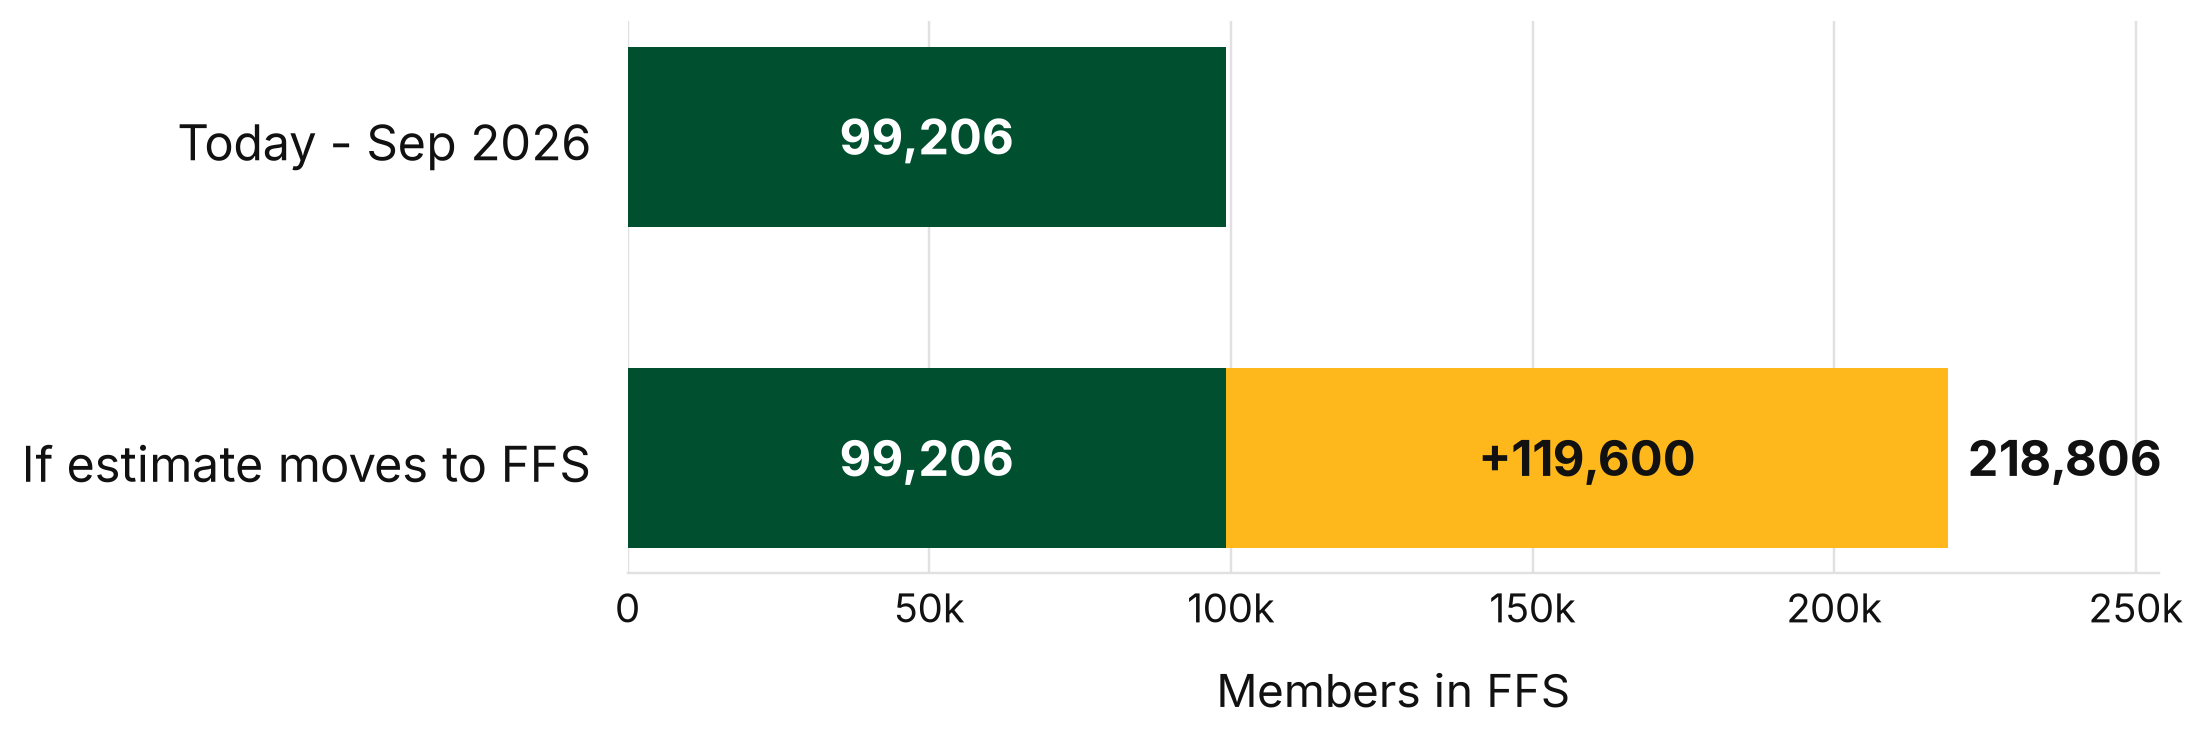

In [26]:
ffs_now = val("Already in FFS, two counties")
iehp_est = val("IEHP estimated transitioning")
ffs_after = ffs_now + iehp_est

from matplotlib import font_manager
import matplotlib.pyplot as plt

font_dir = root / "analysis_outputs" / "slide_exports" / "fonts"
for font_file in (font_dir / "Inter-Regular.ttf", font_dir / "Inter-Bold.ttf"):
    if not font_file.is_file():
        raise FileNotFoundError(f"Bundled Inter font not found: {font_file}")
    font_manager.fontManager.addfont(str(font_file))

cpp_green, cpp_gold = "#005030", "#FFB81C"
ink, grid = "#111111", "#E1E1E1"
plt.rcParams.update({
    "font.family": "Inter", "font.size": 15, "text.color": ink,
    "axes.labelcolor": ink, "xtick.color": ink, "ytick.color": ink,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": grid, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": grid, "grid.linewidth": 0.8, "svg.fonttype": "none",
})

export_dir = root / "analysis_outputs" / "slide_exports"
export_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(12, 3.8))
positions = [1, 0]
ax.barh(positions[0], ffs_now, height=0.56, color=cpp_green, zorder=3)
ax.barh(positions[1], ffs_now, height=0.56, color=cpp_green, zorder=3)
ax.barh(positions[1], iehp_est, left=ffs_now, height=0.56, color=cpp_gold, zorder=3)
ax.set_yticks(positions, ["Today - Sep 2026", "If estimate moves to FFS"])
ax.tick_params(axis="y", length=0, labelsize=16, pad=12)
ax.tick_params(axis="x", length=0, labelsize=13)
ax.set_xlabel("Members in FFS", fontsize=15, labelpad=10)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, ffs_after * 1.16)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k" if x else "0"))
ax.text(ffs_now / 2, positions[0], f"{ffs_now:,}", ha="center", va="center", color="white", fontsize=16, fontweight="bold")
ax.text(ffs_now / 2, positions[1], f"{ffs_now:,}", ha="center", va="center", color="white", fontsize=16, fontweight="bold")
ax.text(ffs_now + iehp_est / 2, positions[1], f"+{iehp_est:,}", ha="center", va="center", color=ink, fontsize=16, fontweight="bold")
ax.text(ffs_after + ffs_after * 0.015, positions[1], f"{ffs_after:,}", ha="left", va="center", color=ink, fontsize=16, fontweight="bold")
fig.subplots_adjust(left=0.30, right=0.88, top=0.93, bottom=0.27)

png_path = export_dir / "ffs_enrollment_scale_CPP_Inter.png"
svg_path = export_dir / "ffs_enrollment_scale_CPP_Inter.svg"
fig.savefig(png_path, dpi=220, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.close(fig)
print("Slide images exported to:", export_dir.relative_to(root))
print("PNG:", png_path.name)
print("SVG:", svg_path.name)
display(Image(filename=str(png_path)))

## 9. What happens to IEHP revenue and costs?

This simple waterfall uses the financial workbook results for IEHP's 119,600-member estimate. It shows lost revenue, costs IEHP would no longer pay, and the remaining net impact. Values are rounded planning estimates, not an IEHP forecast.

Run the cell below to export the image files to `analysis_outputs/slide_exports/`.

Slide images exported to: analysis_outputs\slide_exports
PNG: financial_iehp_estimate_waterfall_CPP_Inter.png
SVG: financial_iehp_estimate_waterfall_CPP_Inter.svg


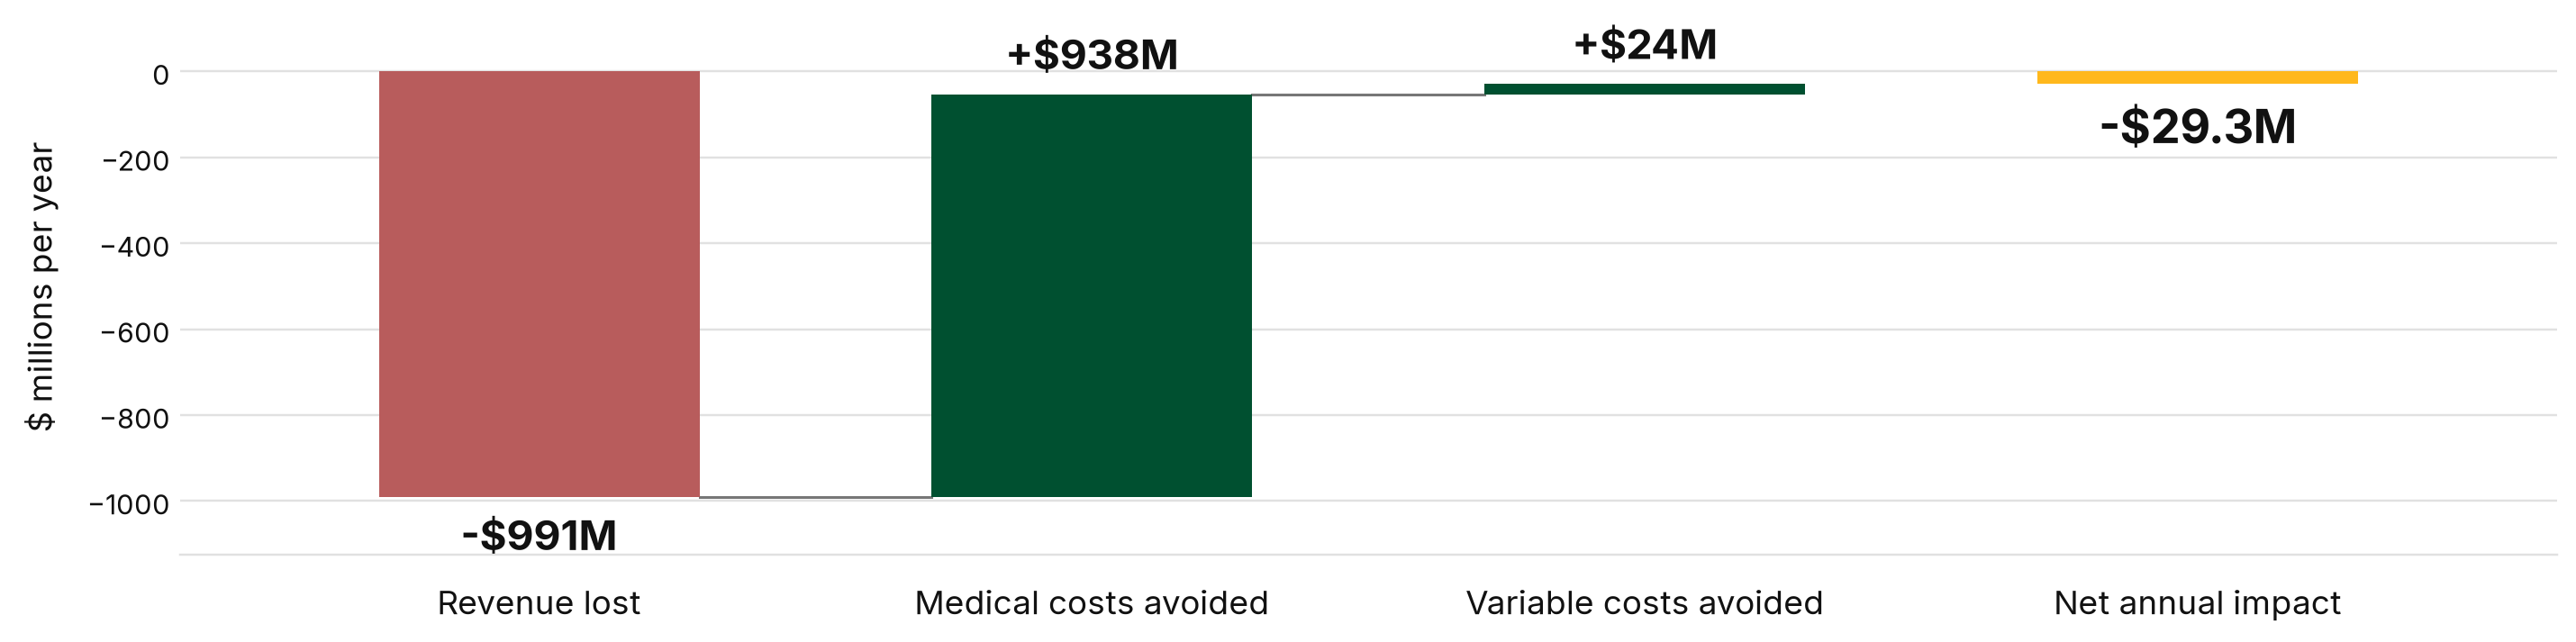

In [27]:
def millions_from_label(value):
    return float(str(value).replace("$", "").replace(",", "").replace("M", ""))

revenue_lost = abs(millions_from_label(case["Revenue lost"]))
medical_avoided = millions_from_label(case["Medical bills avoided"])
variable_avoided = millions_from_label(case["Variable operating costs avoided"])
net_impact = millions_from_label(case["NET EFFECT ON IEHP"])

from matplotlib import font_manager
import matplotlib.pyplot as plt

font_dir = root / "analysis_outputs" / "slide_exports" / "fonts"
for font_file in (font_dir / "Inter-Regular.ttf", font_dir / "Inter-Bold.ttf"):
    if not font_file.is_file():
        raise FileNotFoundError(f"Bundled Inter font not found: {font_file}")
    font_manager.fontManager.addfont(str(font_file))

cpp_green, cpp_gold = "#005030", "#FFB81C"
ink, grid = "#111111", "#E1E1E1"
plt.rcParams.update({
    "font.family": "Inter", "font.size": 13, "text.color": ink,
    "axes.labelcolor": ink, "xtick.color": ink, "ytick.color": ink,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": grid, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": grid, "grid.linewidth": 0.8, "svg.fonttype": "none",
})

export_dir = root / "analysis_outputs" / "slide_exports"
export_dir.mkdir(parents=True, exist_ok=True)
labels = ["Revenue lost", "Medical costs avoided", "Variable costs avoided", "Net annual impact"]
changes = [-revenue_lost, medical_avoided, variable_avoided]
starts = [0, -revenue_lost, -revenue_lost + medical_avoided]
ends = [starts[i] + changes[i] for i in range(len(changes))]

fig, ax = plt.subplots(figsize=(13.33, 5.4))
#fig.suptitle("Most lost revenue is offset by costs IEHP no longer pays", x=0.08, y=0.96, ha="left", fontsize=22, fontweight="bold", color=ink)
#fig.text(0.08, 0.88, "Plus signs show costs avoided; they reduce the revenue loss.", ha="left", fontsize=13, color=ink)
bar_width = 0.58
for i, (start, end) in enumerate(zip(starts, ends)):
    value = changes[i]
    color = "#B85C5C" if i == 0 else cpp_green
    ax.bar(i, abs(value), bottom=min(start, end), width=bar_width, color=color, zorder=3)
    if i < len(changes) - 1:
        ax.plot([i + bar_width / 2, i + 1 - bar_width / 2], [end, end], color="#777777", linewidth=1)
    label = f"-${revenue_lost:,.0f}M" if i == 0 else f"+${value:,.0f}M"
    y_text = min(start, end) - 30 if i == 0 else max(start, end) + 35
    ax.text(i, y_text, label, ha="center", va="top" if i == 0 else "bottom", fontsize=15, fontweight="bold", color=ink)

ax.bar(3, abs(net_impact), bottom=min(0, net_impact), width=bar_width, color=cpp_gold, zorder=3)
ax.text(3, net_impact - 32, f"-${abs(net_impact):,.1f}M", ha="center", va="top", fontsize=17, fontweight="bold", color=ink)
ax.set_xticks(range(4), labels)
ax.tick_params(axis="x", length=0, labelsize=12, pad=10, colors=ink)
ax.tick_params(axis="y", length=0, labelsize=10, colors=ink)
ax.set_ylabel("$ millions per year", fontsize=12, labelpad=10)
ax.set_ylim(-1125, 120)
ax.set_xlim(-0.65, 3.65)
ax.grid(axis="x", visible=False)
#fig.text(0.08, 0.04, "At IEHP's 119,600-member estimate. Rounded workbook-based planning estimate; not an IEHP forecast.", ha="left", fontsize=10, color=ink)
fig.subplots_adjust(left=0.08, right=0.98, top=0.75, bottom=0.25)

png_path = export_dir / "financial_iehp_estimate_waterfall_CPP_Inter.png"
svg_path = export_dir / "financial_iehp_estimate_waterfall_CPP_Inter.svg"
fig.savefig(png_path, dpi=220, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.close(fig)
print("Slide images exported to:", export_dir.relative_to(root))
print("PNG:", png_path.name)
print("SVG:", svg_path.name)
display(Image(filename=str(png_path)))